<a href="https://colab.research.google.com/github/Argyrhspet1/MachineLearning_Project1/blob/main/LinearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Import Libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

#Load Dataset

In [24]:
data=pd.read_csv("/diabetes.csv")

In [25]:
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


#Convert DataFrame to Numpy

In [27]:
input_df=data.drop(columns=["Glucose"])
target_df=data["Glucose"]

x=input_df.to_numpy()
y=target_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

#Split Dataset to Train-Test

In [28]:
seed=0
test_size=0.3

X_train, X_test, y_train, y_test=train_test_split(x, y, test_size=test_size,random_state=seed)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((537, 8), (231, 8), (537,), (231,))

#Create a Linear Regression Model

In [29]:
model=LinearRegression()

In [30]:
model.fit(X_train, y_train)

LinearRegression()

#Evaluate Model on Test Set

In [31]:
y_pred=model.predict(X_test)
y_pred

array([122.79380469, 107.56232968, 107.0412442 , 151.6690938 ,
       107.23107366, 103.14898397, 140.92320662, 153.35010657,
       122.22269249, 132.05628899, 144.73125093, 161.62010307,
       120.1997158 , 107.96882015, 107.74485469, 103.16223192,
       135.23056527,  96.56766055, 116.63618994, 107.56667467,
       131.5643152 , 135.5025461 ,  92.02985352, 111.62943974,
       110.0670277 ,  96.64247521, 103.50579597, 118.95595646,
        96.68581823, 106.3185298 , 121.51598623, 102.32553815,
       113.83963627, 110.42441691, 101.83446714, 138.74159814,
       138.82998248, 105.07326009,  98.096591  , 106.77433103,
       110.61826364, 110.80877089, 105.82495568, 123.17321497,
       181.06586478,  85.04410092,  96.90115182, 131.38985361,
       127.89827218, 133.24733507, 108.50813461, 102.17463445,
       152.59828502, 102.78497006, 120.7815875 ,  94.58111724,
        99.09761517, 144.56197023, 129.19802969, 110.57783196,
       152.39913274, 130.3545672 , 102.45793483, 127.04

In [32]:
mse=mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {round(mse*100,2)}")

Mean Squared Error: 68520.98


In [33]:
mae= mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error: {round(mae*100,2)}")

Mean Absolute Error: 2002.26


Mean Absolute Error is less sensitive to outliers while Mean Squared Error penaltizes a lot more higher values  therefore, MAE is preferable when a robust and interpretable measure of prediction error is desired, whereas MSE is useful when larger errors should receive greater penalties.




#Data Normalization

In [34]:
scaler=StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [35]:
X_train=scaler.transform(X_train)
X_test=scaler.transform(X_test)

#Model Training-Evaluation

In [36]:
model.fit(X_train, y_train)

LinearRegression()

In [37]:
y_pred=model.predict(X_test)
y_pred

array([122.79380469, 107.56232968, 107.0412442 , 151.6690938 ,
       107.23107366, 103.14898397, 140.92320662, 153.35010657,
       122.22269249, 132.05628899, 144.73125093, 161.62010307,
       120.1997158 , 107.96882015, 107.74485469, 103.16223192,
       135.23056527,  96.56766055, 116.63618994, 107.56667467,
       131.5643152 , 135.5025461 ,  92.02985352, 111.62943974,
       110.0670277 ,  96.64247521, 103.50579597, 118.95595646,
        96.68581823, 106.3185298 , 121.51598623, 102.32553815,
       113.83963627, 110.42441691, 101.83446714, 138.74159814,
       138.82998248, 105.07326009,  98.096591  , 106.77433103,
       110.61826364, 110.80877089, 105.82495568, 123.17321497,
       181.06586478,  85.04410092,  96.90115182, 131.38985361,
       127.89827218, 133.24733507, 108.50813461, 102.17463445,
       152.59828502, 102.78497006, 120.7815875 ,  94.58111724,
        99.09761517, 144.56197023, 129.19802969, 110.57783196,
       152.39913274, 130.3545672 , 102.45793483, 127.04

In [38]:
mse=mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {round(mse*100,2)}")

Mean Squared Error: 68520.98


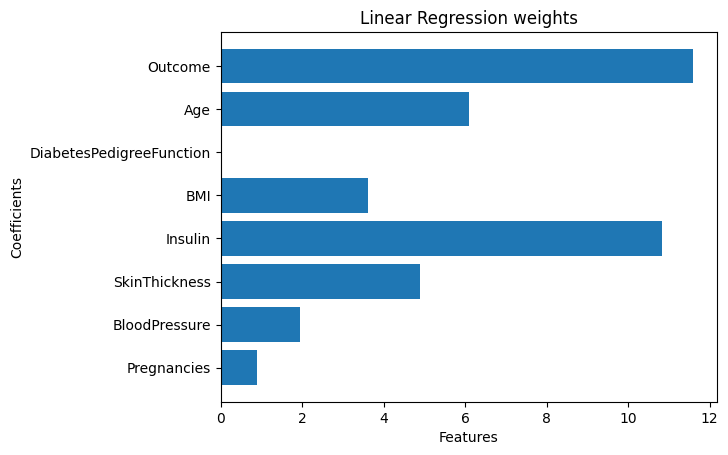

In [39]:
coeffs=model.coef_
importance_weights=np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title("Linear Regression weights")
plt.xlabel("Features")
plt.ylabel("Coefficients")
plt.show()